# Getaround – Analyse des retards au retour : quel délai minimum entre deux locations ?

**Problème.** Quand un conducteur rend la voiture en retard, le conducteur suivant attend, voire annule. Getaround veut imposer un **délai minimum** entre deux locations d'une même voiture : une voiture n'apparaît plus dans la recherche si le créneau demandé est trop proche d'une location déjà réservée.

**Le compromis.** Ce délai supprime des frictions mais bloque aussi des locations, donc du revenu. Le Product Manager doit choisir :
- le **seuil** : combien de minutes ?
- le **périmètre** : toutes les voitures, ou seulement les voitures *Connect* ?

**Questions traitées.** À quelle fréquence les conducteurs sont-ils en retard, et quel effet sur le suivant ? Combien de locations (et quelle part du revenu) seraient touchées selon le seuil et le périmètre ? Combien de cas problématiques seraient résolus ?

Les calculs sont dans `dashboard/delay_lib.py`, partagé avec le dashboard Streamlit pour que les deux donnent les mêmes chiffres.

In [1]:
import sys; sys.path.insert(0, "../dashboard")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from delay_lib import charger, impact, courbe, SCOPES
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110

loc, paires = charger("../data/get_around_delay_analysis.xlsx")
print(f"{len(loc):,} locations, {loc.car_id.nunique():,} voitures")
display(pd.crosstab(loc.checkin_type, loc.state, margins=True, margins_name="total"))
print("Valeurs manquantes :", loc.isna().sum()[lambda s: s > 0].to_dict())

21,310 locations, 8,143 voitures


state,canceled,ended,total
checkin_type,,,
connect,798,3509,4307
mobile,2467,14536,17003
total,3265,18045,21310


Valeurs manquantes : {'delay_at_checkout_in_minutes': 4964, 'previous_ended_rental_id': 19469, 'time_delta_with_previous_rental_in_minutes': 19469}


**Lecture.** 21 310 locations sur 8 143 voitures. 80 % passent par le parcours *Mobile* (contrat signé sur le téléphone du propriétaire), 20 % par *Connect* (le conducteur ouvre la voiture avec son téléphone, sans rencontrer le propriétaire). 15 % des locations sont annulées, un peu plus en Connect (18,5 %) qu'en Mobile (14,5 %).

Valeurs manquantes : le retard au retour manque pour les 3 264 locations annulées sans mesure (logique) et pour 1 700 locations terminées. La location précédente n'est renseignée que si elle s'est terminée moins de 12 heures avant : c'est le cas de 1 841 locations seulement.

## 1. À quelle fréquence les conducteurs rendent-ils la voiture en retard ?

Retard connu pour 16,345 locations terminées sur 18,045 (1,700 sans mesure)
En retard : 57.5% | retard médian : 9 min | 90e centile : 193 min | max : 71,084 min


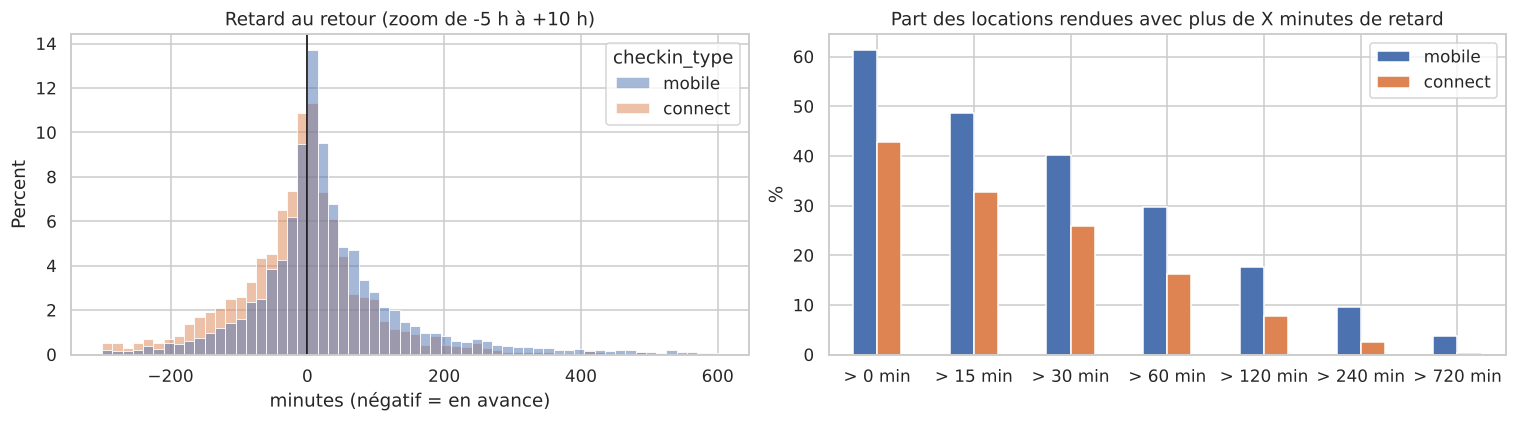

,mobile,connect,toutes
> 0 min,61.4,42.9,57.5
> 15 min,48.7,32.6,45.4
> 30 min,40.2,25.8,37.2
> 60 min,29.6,16.3,26.8
> 120 min,17.7,7.7,15.6
> 240 min,9.6,2.6,8.2
> 720 min,3.7,0.4,3.0


In [2]:
fin = loc[loc.state == "ended"]
retard = fin.delay_at_checkout_in_minutes.dropna()
print(f"Retard connu pour {len(retard):,} locations terminées sur {len(fin):,} ({fin.delay_at_checkout_in_minutes.isna().sum():,} sans mesure)")
print(f"En retard : {(retard > 0).mean():.1%} | retard médian : {retard.median():.0f} min | 90e centile : {retard.quantile(0.9):.0f} min | max : {retard.max():,.0f} min")

seuils = [0, 15, 30, 60, 120, 240, 720]
part = pd.DataFrame({t: [(fin[fin.checkin_type == t].delay_at_checkout_in_minutes.dropna() > s).mean() * 100 for s in seuils]
                     for t in ["mobile", "connect"]}, index=[f"> {s} min" for s in seuils])
part["toutes"] = [(retard > s).mean() * 100 for s in seuils]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=fin.dropna(subset=["delay_at_checkout_in_minutes"]), x="delay_at_checkout_in_minutes", hue="checkin_type",
             binrange=(-300, 600), bins=60, stat="percent", common_norm=False, ax=axes[0])
axes[0].axvline(0, color="black", lw=1); axes[0].set(title="Retard au retour (zoom de -5 h à +10 h)", xlabel="minutes (négatif = en avance)")
part[["mobile", "connect"]].plot.bar(ax=axes[1], color=["#4c72b0", "#dd8452"], rot=0)
axes[1].set(title="Part des locations rendues avec plus de X minutes de retard", ylabel="%")
plt.tight_layout(); plt.show()
part.round(1)

**Lecture.** Plus de la moitié des locations (57,5 %) sont rendues en retard, mais souvent de peu : retard médian de 9 minutes. La queue est longue : 27 % ont plus d'une heure de retard, 3 % plus de 12 heures (quelques valeurs extrêmes jusqu'à 49 jours, probablement des oublis de check-out).

Les conducteurs **Connect sont nettement plus ponctuels** : 43 % en retard contre 61 % en Mobile, et 16 % contre 30 % au-delà d'une heure. En Mobile, le retour dépend du rendez-vous avec le propriétaire.

## 2. Locations consécutives : quand le retard gêne-t-il le conducteur suivant ?

1,841 locations ont une location précédente sur la même voiture à moins de 12 h (8.6% des locations) ; retard précédent inconnu pour 112
Cas problématiques (retard du précédent > délai prévu) : 218 sur 1729 (12.6%)
Attente du conducteur suivant dans ces cas (min) : {'count': 218.0, 'mean': 178.0, 'std': 925.0, 'min': 1.0, '50%': 26.0, '75%': 80.0, '90%': 214.0, 'max': 12548.0}


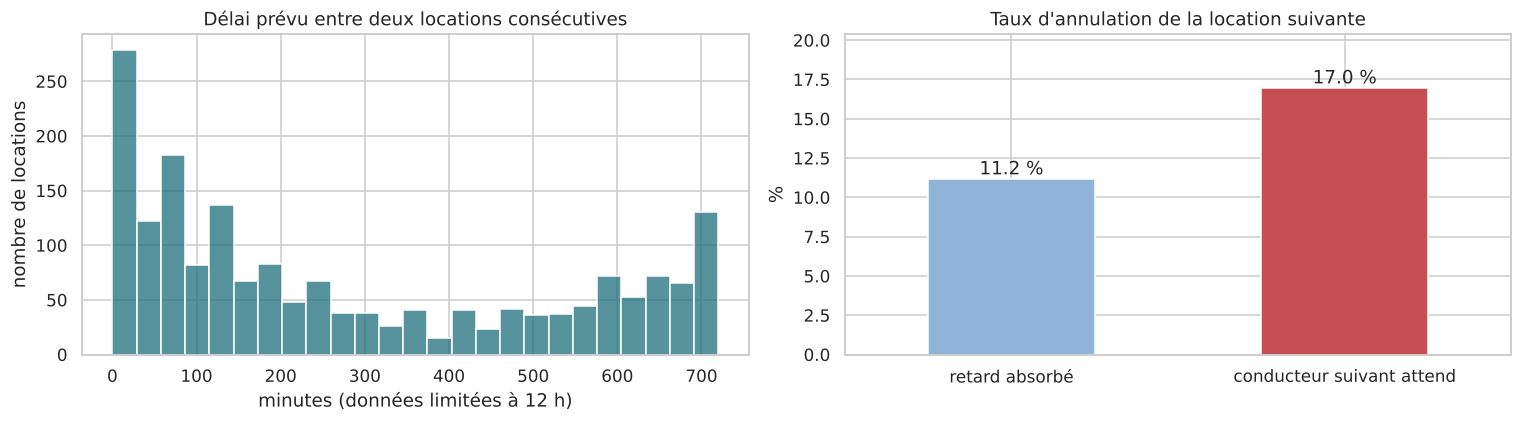

Par type de check-in :


,paires,cas_problematiques,part
checkin_type,,,
connect,791,69,0.087
mobile,938,149,0.159


In [3]:
print(f"{len(paires):,} locations ont une location précédente sur la même voiture à moins de 12 h "
      f"({len(paires) / len(loc):.1%} des locations) ; retard précédent inconnu pour {paires.retard_precedent.isna().sum()}")
connus = paires.dropna(subset=["retard_precedent"])
print(f"Cas problématiques (retard du précédent > délai prévu) : {connus.probleme.sum()} sur {len(connus)} ({connus.probleme.mean():.1%})")
print("Attente du conducteur suivant dans ces cas (min) :", connus[connus.probleme].attente.describe(percentiles=[.5, .75, .9]).round(0).to_dict())

annul = connus.groupby("probleme").state.apply(lambda s: (s == "canceled").mean() * 100).rename({False: "retard absorbé", True: "conducteur suivant attend"})
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(paires.delai_prevu, bins=25, ax=axes[0], color="#1f6f7d")
axes[0].set(title="Délai prévu entre deux locations consécutives", xlabel="minutes (données limitées à 12 h)")
annul.plot.bar(ax=axes[1], color=["#8fb3d9", "#c44e52"], rot=0)
for c in axes[1].containers: axes[1].bar_label(c, fmt="%.1f %%")
axes[1].set_ylim(0, annul.max() * 1.2); axes[0].set_ylabel("nombre de locations")
axes[1].set(title="Taux d'annulation de la location suivante", ylabel="%", xlabel="")
plt.tight_layout(); plt.show()
print("Par type de check-in :")
connus.groupby("checkin_type").agg(paires=("probleme", "size"), cas_problematiques=("probleme", "sum"), part=("probleme", "mean")).round(3)

**Lecture.** Le retard ne pose problème que si la voiture est relouée peu après. 1 841 locations (8,6 %) suivent une autre location de la même voiture à moins de 12 heures ; 279 sont même prévues **bout à bout** (délai de 0 minute).

Parmi les 1 729 paires dont le retard précédent est connu, **218 (12,6 %) sont problématiques** : le conducteur précédent rend la voiture après l'heure de départ prévue du suivant. L'attente médiane est de 26 minutes, et dépasse 80 minutes pour un quart des cas.

Effet sur le conducteur suivant : 17,0 % des locations suivantes sont annulées quand il doit attendre, contre 11,2 % sinon (+5,8 points). Les cas problématiques sont deux fois plus fréquents en Mobile (15,9 %) qu'en Connect (8,7 %).

## 3. Le compromis seuil × périmètre

Pour un seuil *S*, toute location dont le délai prévu avec la précédente est inférieur à *S* n'aurait pas pu être réservée. On compte :
- les **locations bloquées** (et, parmi elles, celles qui ont eu lieu : **proxy du revenu perdu**, faute de prix dans ces données) ;
- les **cas problématiques résolus** : ceux où le conducteur suivant a attendu et que le seuil aurait évités.

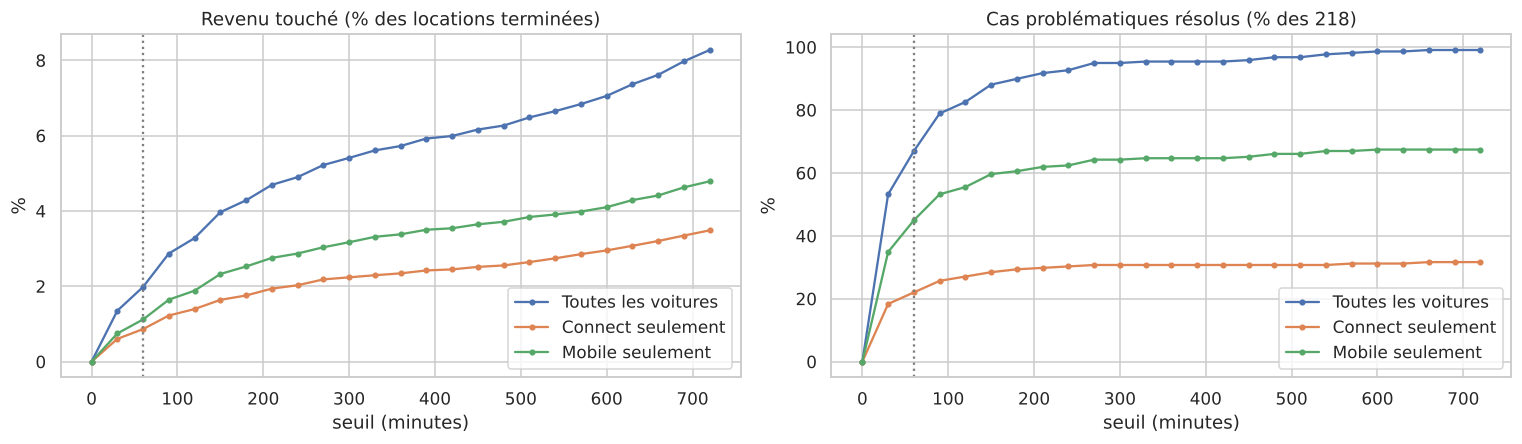

locations bloquées  % du revenu (proxy)  \
périmètre           seuil                                            
Toutes les voitures 30                    279                  1.4   
                    60                    401                  2.0   
                    90                    584                  2.9   
                    120                   666                  3.3   
                    180                   870                  4.3   
                    240                  1001                  4.9   
Connect seulement   30                    131                  0.6   
                    60                    181                  0.9   
                    90                    260                  1.2   
                    120                   295                  1.4   
                    180                   372                  1.8   
                    240                   430                  2.0   
Mobile seulement    30                    148                  0.7   
                    60                    220                  1.1   
                    90                    324                  1.6   
                    120                   371                  1.9   
                    180                   498                  2.5   
                    240                   571                  2.9   

                           cas résolus  % de tous les cas problématiques  
périmètre           seuil                                                 
Toutes les voitures 30             116                              53.2  
                    60             146                              67.0  
                    90             172                              78.9  
                    120            180                              82.6  
                    180            196                              89.9  
                    240            202                              92.7  
Connect seulement   30              40                              18.3  
                    60              48                              22.0  
                    90              56                              25.7  
                    120             59                              27.1  
                    180             64                              29.4  
                    240             66                              30.3  
Mobile seulement    30              76                              34.9  
                    60              98                              45.0  
                    90             116                              53.2  
                    120            121                              55.5  
                    180            132                              60.6  
                    240            136                              62.4

In [4]:
c = courbe(loc, paires)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for nom, g in c.groupby("périmètre", sort=False):
    axes[0].plot(g.seuil, g["% du revenu (proxy)"], marker="o", ms=3, label=nom)
    axes[1].plot(g.seuil, g["% de tous les cas problématiques"], marker="o", ms=3, label=nom)
axes[0].set(title="Revenu touché (% des locations terminées)", xlabel="seuil (minutes)", ylabel="%")
axes[1].set(title="Cas problématiques résolus (% des 218)", xlabel="seuil (minutes)", ylabel="%")
for ax in axes: ax.axvline(60, color="grey", ls=":"); ax.legend()
plt.tight_layout(); plt.show()

colonnes = ["locations bloquées", "% du revenu (proxy)", "cas résolus", "% de tous les cas problématiques"]
tableau = c[c.seuil.isin([30, 60, 90, 120, 180, 240])].set_index(["périmètre", "seuil"])[colonnes]
tableau.round(1)

**Lecture.** Un seuil bloque toute location prévue moins de *S* minutes après la précédente.

- **Toutes les voitures** : 60 minutes évitent 146 des 218 cas problématiques (67 %) en touchant 2,0 % du revenu ; 120 minutes en évitent 180 (83 %) pour 3,3 %. Au-delà, la courbe des cas évités plafonne (93 % à 240 minutes) alors que le revenu touché continue de monter.
- **Connect seulement** : le revenu touché est faible (0,9 % à 60 minutes), mais seuls 69 des 218 cas problématiques concernent des voitures Connect. Même avec 12 heures de délai, on n'en éviterait que 32 %.

Le revenu est estimé par la part des locations terminées bloquées : c'est une borne haute, car un conducteur bloqué peut choisir un autre créneau ou une autre voiture.

In [5]:
# Efficacité : combien de locations faut-il bloquer pour éviter un cas problématique ?
c["locations bloquées par cas résolu"] = c["locations bloquées"] / c["cas résolus"].replace(0, np.nan)
c[c.seuil.isin([30, 60, 120, 240, 720])].pivot(index="seuil", columns="périmètre", values="locations bloquées par cas résolu").round(1)

périmètre,Connect seulement,Mobile seulement,Toutes les voitures
seuil,,,
30,3.3,1.9,2.4
60,3.8,2.2,2.7
120,5.0,3.1,3.7
240,6.5,4.2,5.0
720,10.9,6.5,7.9


**Lecture.** Le coût d'un cas évité, en locations bloquées, augmente avec le seuil : sur toutes les voitures, 2,4 locations bloquées par cas évité à 30 minutes, 2,7 à 60, 3,7 à 120 et 7,9 à 720. Le périmètre **Mobile** est le plus efficace (2,2 à 60 minutes), car c'est là que se concentrent les retards ; Connect seul est le moins efficace (3,8 à 60 minutes).

## 4. Recommandation

| Option | Cas problématiques évités | Revenu touché (proxy) | Locations bloquées par cas évité |
|---|---|---|---|
| Toutes les voitures, 60 min | 146 / 218 (67 %) | 2,0 % | 2,7 |
| **Toutes les voitures, 90 min** | **172 / 218 (79 %)** | **2,9 %** | **3,4** |
| Toutes les voitures, 120 min | 180 / 218 (83 %) | 3,3 % | 3,7 |
| Connect seulement, 120 min | 59 / 218 (27 %) | 1,4 % | 5,0 |

**Recommandation : activer le délai sur toutes les voitures, entre 60 et 90 minutes.** C'est la zone où la courbe des cas évités est encore raide : au-delà de 120 minutes, chaque cas évité coûte de plus en plus de locations. Limiter la fonctionnalité aux voitures Connect protégerait le revenu mais laisserait de côté plus des deux tiers des problèmes, qui viennent des voitures Mobile.

**Limites.** Pas de prix dans ces données (revenu estimé par le nombre de locations), seules les locations à moins de 12 heures d'intervalle sont renseignées, et l'effet réel d'un blocage (report ou perte) est inconnu : à mesurer par un test A/B sur une partie des voitures avant de généraliser.